# Linear Regression: From First Principles to Practice

Welcome to this comprehensive tutorial on Linear Regression, the foundational algorithm in machine learning and statistical modeling.

## What You'll Learn
- **What is Linear Regression** and why it's fundamental
- **Mathematical foundations** from first principles
- **Hands-on implementation** on a real clinical dataset
- **Model evaluation** and interpretation
- **Assumptions and diagnostics**
- **Advanced techniques** (regularization, polynomial features)
- **Interactive parameter exploration**
- **Real-world best practices**

The worked example is the scikit-learn **diabetes** dataset: ten baseline clinical
measurements from 442 patients, and a quantitative measure of disease progression one
year later. It is a published, fully de-identified research dataset.

---


## 1. Introduction & Setup

First, let's import all necessary libraries and check versions.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.datasets import load_diabetes, make_regression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
import sklearn
from scipy import stats

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)

# Version checks
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

NumPy version: 2.5.3
Pandas version: 3.0.6
Scikit-learn version: 1.9.1


### What is Linear Regression?

**Linear Regression** is a statistical method for modeling the relationship between a dependent variable (target) and one or more independent variables (features) using a linear equation.

#### Key Characteristics:
1. **Simplicity**: Easy to understand and interpret
2. **Speed**: Fast to train and predict
3. **Interpretability**: Clear relationship between features and target
4. **Foundation**: Basis for many advanced algorithms
5. **Statistical Properties**: Well-understood mathematical properties

#### When to Use Linear Regression:
- ✅ **Linear relationships** between features and target
- ✅ **Need for interpretability** (coefficients have clear meaning)
- ✅ **Fast predictions** required
- ✅ **Baseline model** to compare against
- ❌ **Complex non-linear patterns** (try polynomial or other models)
- ❌ **Categorical target** (use classification instead)

---
## 2. Mathematical Foundation

Understanding the mathematics behind linear regression helps you use it more effectively.

### Simple Linear Regression (One Variable)

The equation for simple linear regression:

$$y = \beta_0 + \beta_1 x + \epsilon$$

Where:
- $y$ = target variable (what we predict)
- $x$ = feature variable (what we use to predict)
- $\beta_0$ = intercept (y-value when x=0)
- $\beta_1$ = slope (change in y per unit change in x)
- $\epsilon$ = error term (residual)

### Multiple Linear Regression (Multiple Variables)

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_n x_n + \epsilon$$

In matrix form:
$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\epsilon}$$

### How Do We Find the Best Coefficients?

We minimize the **Sum of Squared Errors (SSE)** using **Ordinary Least Squares (OLS)**:

$$SSE = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

The closed-form solution:
$$\boldsymbol{\beta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

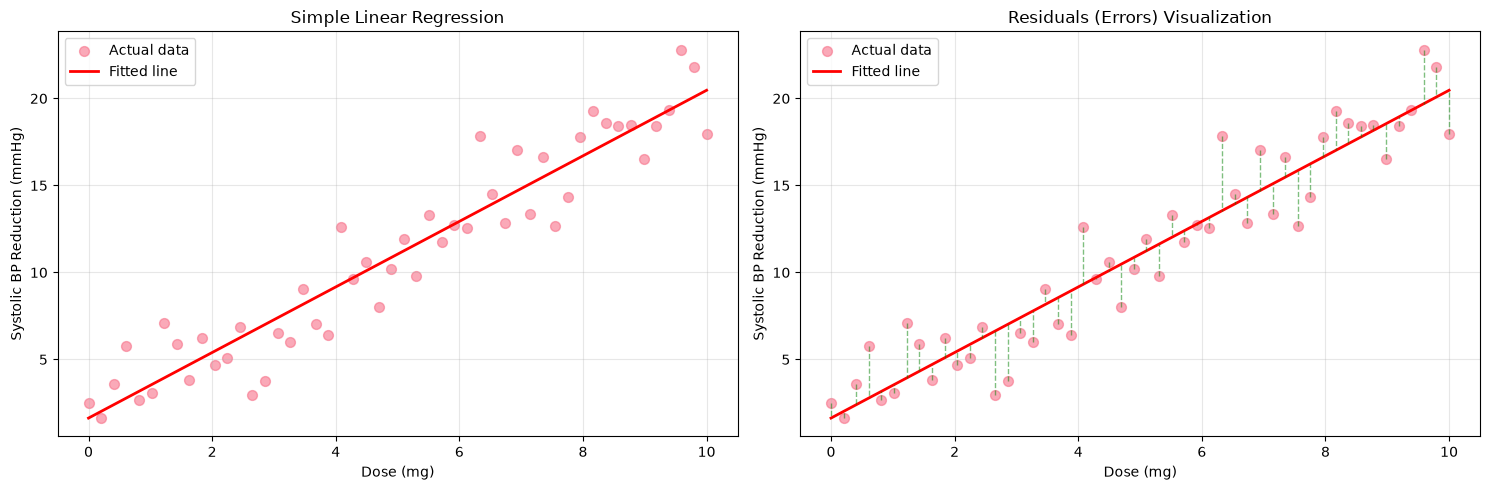

Manual Calculation Results:
Intercept (β₀): 1.6289
Slope (β₁): 1.8840

Model Quality:
Sum of Squared Errors (SSE): 165.0284
Mean Squared Error (MSE): 3.3006
Root Mean Squared Error (RMSE): 1.8167
R² Score: 0.9032

Interpretation:
- For every 1 mg increase in dose, systolic BP falls by a further 1.88 mmHg
- At a zero dose (placebo) the apparent reduction is about 1.63 mmHg
- The model explains 90.3% of the variance in BP reduction


In [2]:
# Visualize simple linear regression concept
np.random.seed(42)

# Simple dose-response data: an antihypertensive drug.
# Over this dose range the fall in systolic blood pressure is close to linear.
# Simulated data - no real patient records are used.
dose_mg = np.linspace(0, 10, 50)
sbp_reduction_mmhg = 1.5 + 2.0 * dose_mg + np.random.normal(0, 2, 50)

# Fit line manually using the formula
dose_mean = dose_mg.mean()
reduction_mean = sbp_reduction_mmhg.mean()

# Calculate slope and intercept
beta_1 = np.sum((dose_mg - dose_mean) * (sbp_reduction_mmhg - reduction_mean)) / np.sum((dose_mg - dose_mean)**2)
beta_0 = reduction_mean - beta_1 * dose_mean

reduction_pred = beta_0 + beta_1 * dose_mg

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: The fitted line
axes[0].scatter(dose_mg, sbp_reduction_mmhg, alpha=0.6, s=50, label='Actual data')
axes[0].plot(dose_mg, reduction_pred, 'r-', linewidth=2, label='Fitted line')
axes[0].set_xlabel('Dose (mg)')
axes[0].set_ylabel('Systolic BP Reduction (mmHg)')
axes[0].set_title('Simple Linear Regression')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Show residuals
axes[1].scatter(dose_mg, sbp_reduction_mmhg, alpha=0.6, s=50, label='Actual data')
axes[1].plot(dose_mg, reduction_pred, 'r-', linewidth=2, label='Fitted line')

# Draw residual lines
for i in range(0, len(dose_mg)):  # Show every residual for clarity
    axes[1].plot([dose_mg[i], dose_mg[i]], [sbp_reduction_mmhg[i], reduction_pred[i]],
                'g--', alpha=0.5, linewidth=1)

axes[1].set_xlabel('Dose (mg)')
axes[1].set_ylabel('Systolic BP Reduction (mmHg)')
axes[1].set_title('Residuals (Errors) Visualization')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate metrics
residuals = sbp_reduction_mmhg - reduction_pred
sse = np.sum(residuals**2)
mse = sse / len(sbp_reduction_mmhg)
rmse = np.sqrt(mse)
r2 = 1 - (sse / np.sum((sbp_reduction_mmhg - reduction_mean)**2))

print("Manual Calculation Results:")
print(f"Intercept (β₀): {beta_0:.4f}")
print(f"Slope (β₁): {beta_1:.4f}")
print(f"\nModel Quality:")
print(f"Sum of Squared Errors (SSE): {sse:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"\nInterpretation:")
print(f"- For every 1 mg increase in dose, systolic BP falls by a further {beta_1:.2f} mmHg")
print(f"- At a zero dose (placebo) the apparent reduction is about {beta_0:.2f} mmHg")
print(f"- The model explains {r2*100:.1f}% of the variance in BP reduction")


### Understanding R² (Coefficient of Determination)

R² measures how well the model fits the data:

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$$

- **R² = 1**: Perfect fit (all points on the line)
- **R² = 0**: Model no better than predicting the mean
- **R² < 0**: Model worse than just using the mean

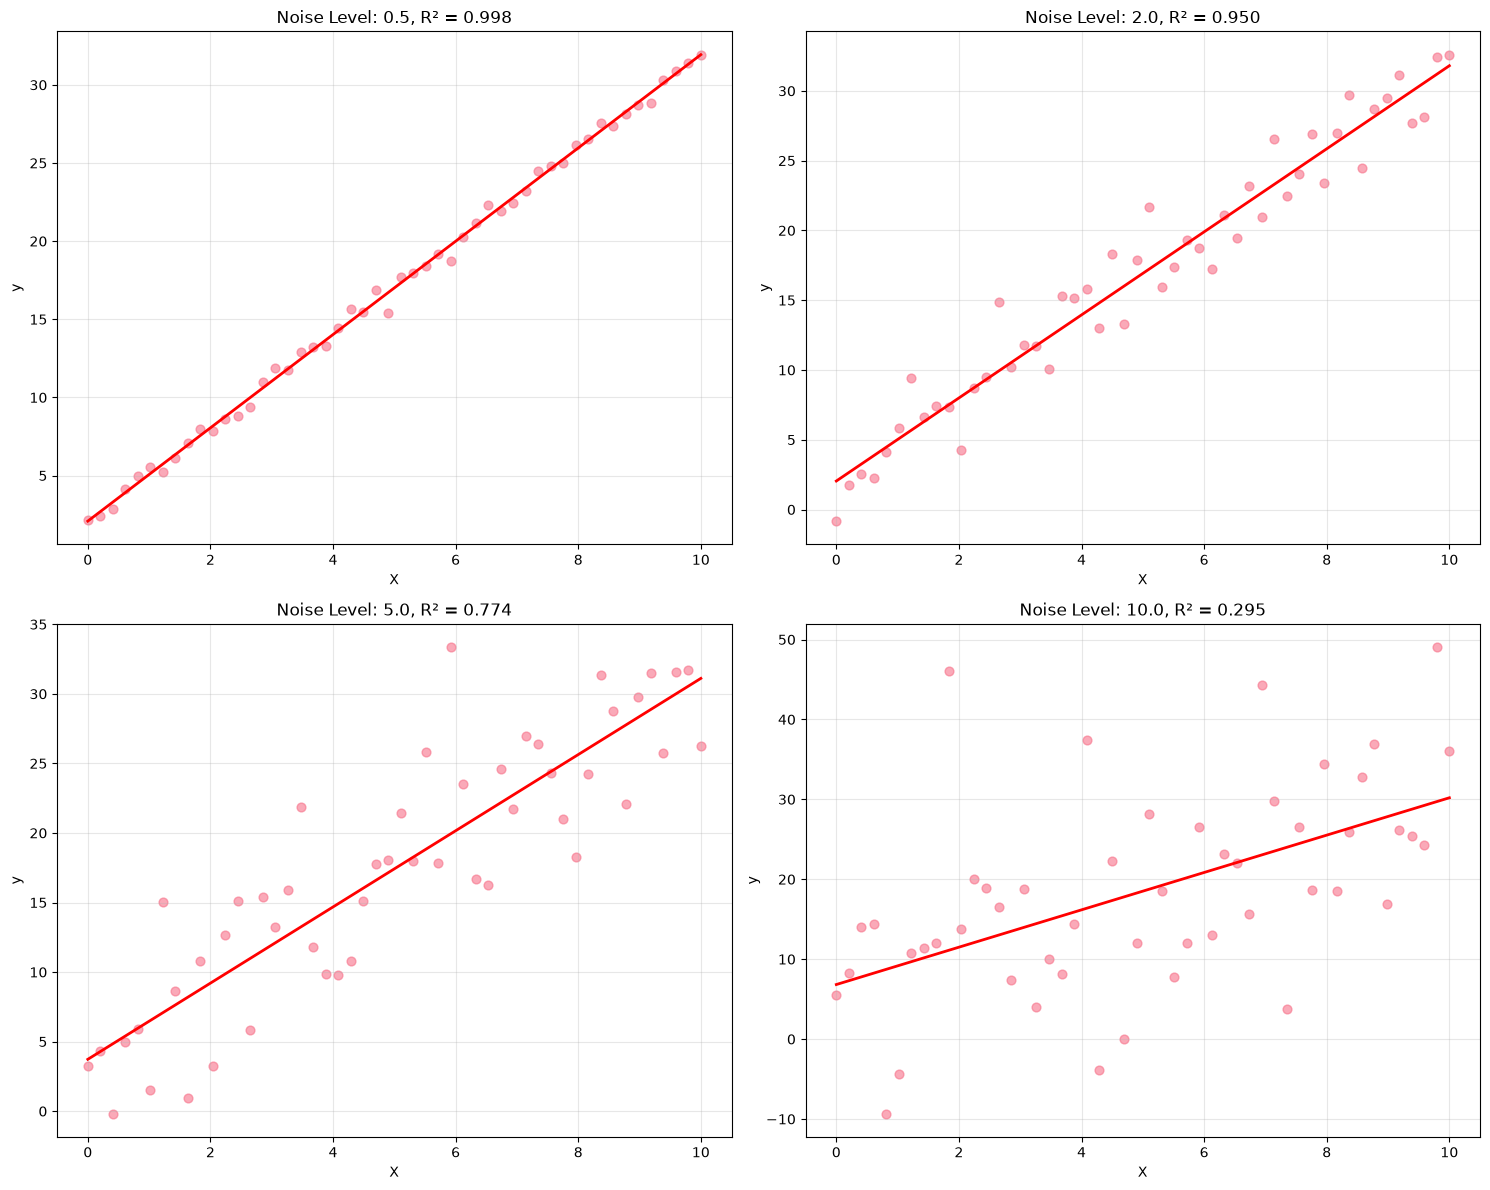

R² Interpretation:
- As noise increases, R² decreases
- Lower R² means more unexplained variance
- High R² alone doesn't guarantee a good model (check assumptions!)


In [3]:
# Visualize different R² values
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

noise_levels = [0.5, 2, 5, 10]
X_demo = np.linspace(0, 10, 50)

for idx, noise in enumerate(noise_levels):
    y_demo = 2 + 3 * X_demo + np.random.normal(0, noise, 50)
    
    # Fit model
    model = LinearRegression()
    model.fit(X_demo.reshape(-1, 1), y_demo)
    y_pred = model.predict(X_demo.reshape(-1, 1))
    r2 = r2_score(y_demo, y_pred)
    
    # Plot
    axes[idx].scatter(X_demo, y_demo, alpha=0.6, s=40)
    axes[idx].plot(X_demo, y_pred, 'r-', linewidth=2)
    axes[idx].set_title(f'Noise Level: {noise:.1f}, R² = {r2:.3f}')
    axes[idx].set_xlabel('X')
    axes[idx].set_ylabel('y')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("R² Interpretation:")
print("- As noise increases, R² decreases")
print("- Lower R² means more unexplained variance")
print("- High R² alone doesn't guarantee a good model (check assumptions!)")

---
## 3. Hands-on Implementation with Real Clinical Data

Now let's work with a real dataset: the scikit-learn **diabetes** dataset.

Ten baseline variables — age, sex, body mass index, mean arterial blood pressure and six
blood serum measurements — were recorded for 442 patients with diabetes. The target is a
**quantitative measure of disease progression one year after baseline**: higher means the
disease advanced further. The dataset is published and fully de-identified.

Note that the ten predictors have already been mean-centred and scaled, so a coefficient
is read as "effect per standard-deviation-like unit", not per mmol/L.


In [4]:
# Load the diabetes disease-progression dataset
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

# Readable clinical names for the ten baseline measurements
feature_names = [
    'Age',            # age in years
    'Sex',            # sex
    'BMI',            # body mass index
    'MeanBP',         # average blood pressure
    'TotalChol',      # s1: total serum cholesterol
    'LDL',            # s2: low-density lipoprotein
    'HDL',            # s3: high-density lipoprotein
    'CholHDLRatio',   # s4: total cholesterol / HDL
    'LogTriglyceride',# s5: log of serum triglyceride level
    'BloodGlucose'    # s6: blood sugar level
]

# Create DataFrame for easier exploration
df = pd.DataFrame(X, columns=feature_names)
df['DiseaseProgression'] = y

print(f"Dataset shape: {X.shape}")
print(f"Features: {feature_names}")
print(f"Target: Disease progression one year after baseline (25-346, higher = worse)")
print(f"\nDataset statistics:")
print(df.describe())


Dataset shape: (442, 10)
Features: ['Age', 'Sex', 'BMI', 'MeanBP', 'TotalChol', 'LDL', 'HDL', 'CholHDLRatio', 'LogTriglyceride', 'BloodGlucose']
Target: Disease progression one year after baseline (25-346, higher = worse)

Dataset statistics:
                Age           Sex           BMI        MeanBP     TotalChol  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                LDL           HDL  CholHDLRat

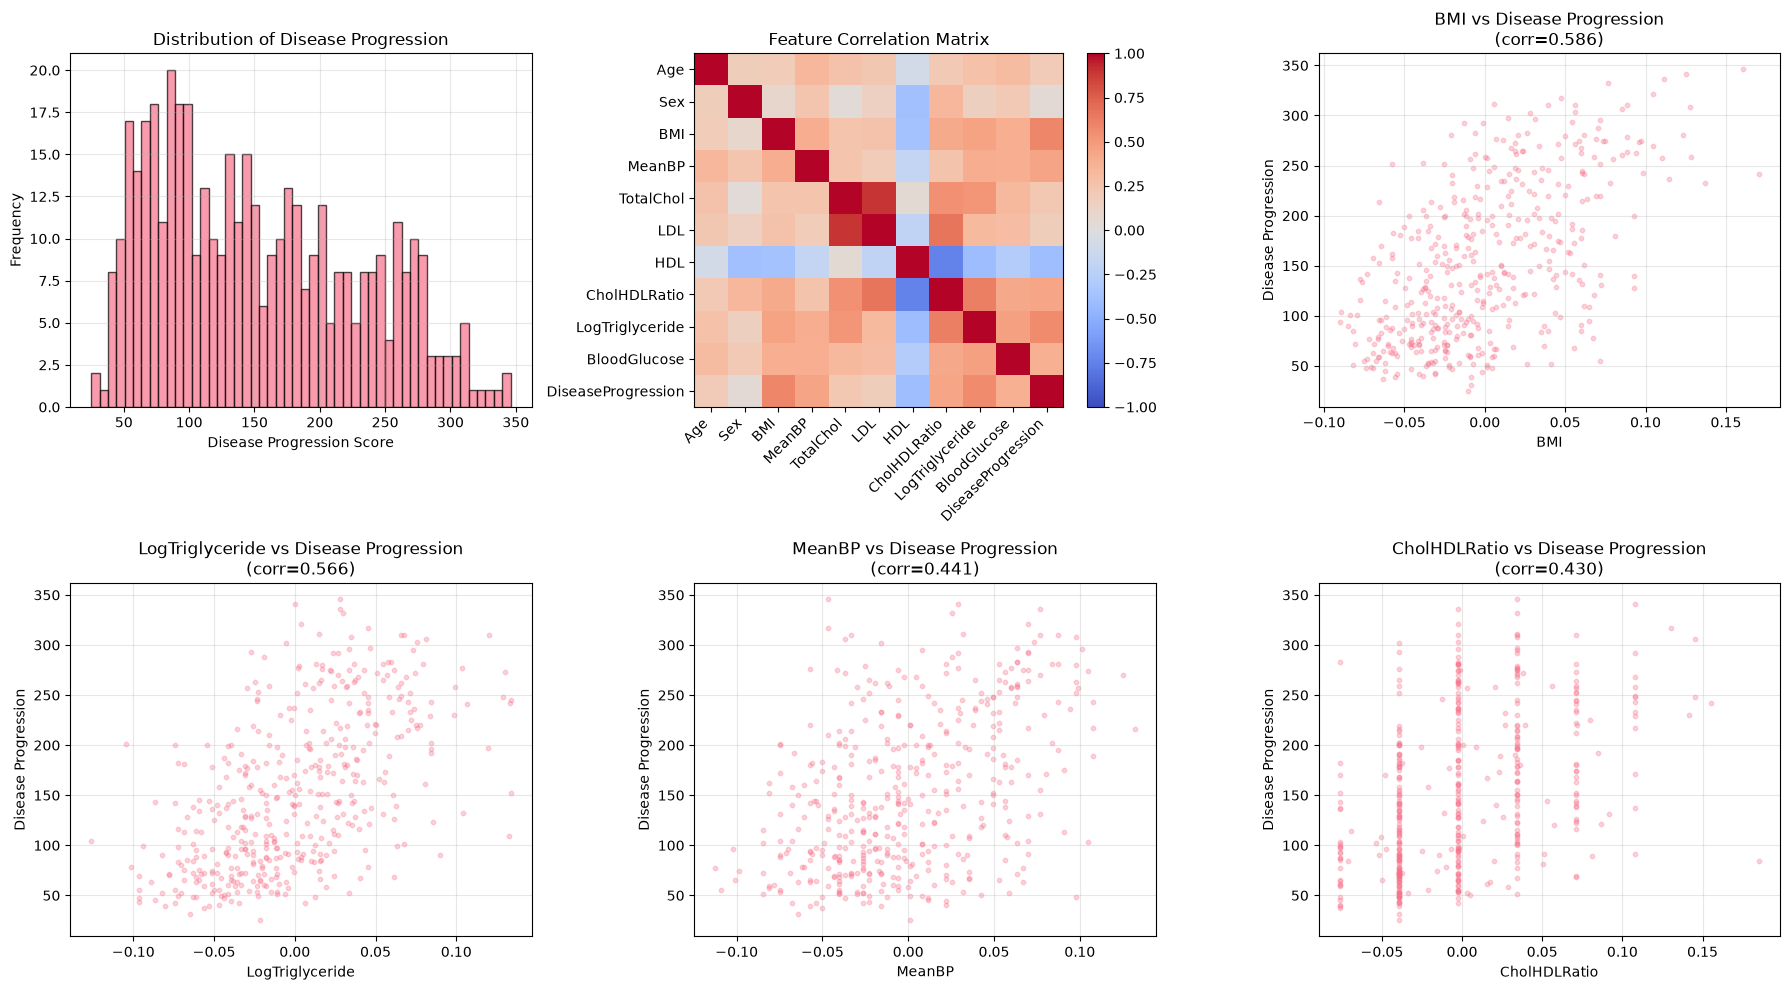


Top 5 correlations with Disease Progression:
BMI                0.586450
LogTriglyceride    0.565883
MeanBP             0.441482
CholHDLRatio       0.430453
BloodGlucose       0.382483
Name: DiseaseProgression, dtype: float64


In [5]:
# Exploratory Data Analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

# Plot distributions and relationships
# Target distribution
axes[0].hist(y, bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Disease Progression')
axes[0].set_xlabel('Disease Progression Score')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

# Correlation heatmap
correlation = df.corr()
im = axes[1].imshow(correlation, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(correlation)))
axes[1].set_yticks(range(len(correlation)))
axes[1].set_xticklabels(correlation.columns, rotation=45, ha='right')
axes[1].set_yticklabels(correlation.columns)
axes[1].set_title('Feature Correlation Matrix')
plt.colorbar(im, ax=axes[1])

# Scatter plots for most correlated features
top_features = correlation['DiseaseProgression'].abs().sort_values(ascending=False)[1:5].index

for idx, feature in enumerate(top_features):
    axes[idx + 2].scatter(df[feature], df['DiseaseProgression'], alpha=0.3, s=10)
    axes[idx + 2].set_xlabel(feature)
    axes[idx + 2].set_ylabel('Disease Progression')
    axes[idx + 2].set_title(f'{feature} vs Disease Progression\n(corr={correlation.loc[feature, "DiseaseProgression"]:.3f})')
    axes[idx + 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTop 5 correlations with Disease Progression:")
print(correlation['DiseaseProgression'].sort_values(ascending=False)[1:6])


In [6]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

# Train a basic linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

# Evaluate the model
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

print("\n" + "="*50)
print("MODEL PERFORMANCE")
print("="*50)
print(f"\nTraining Set:")
print(f"  MSE:  {train_mse:.4f}")
print(f"  RMSE: {np.sqrt(train_mse):.4f} (progression points)")
print(f"  MAE:  {train_mae:.4f} (progression points)")
print(f"  R²:   {train_r2:.4f}")

print(f"\nTest Set:")
print(f"  MSE:  {test_mse:.4f}")
print(f"  RMSE: {np.sqrt(test_mse):.4f} (progression points)")
print(f"  MAE:  {test_mae:.4f} (progression points)")
print(f"  R²:   {test_r2:.4f}")

print(f"\nInterpretation:")
print(f"  The model explains {test_r2*100:.1f}% of variance in disease progression")
print(f"  Average prediction error: {test_mae:.1f} progression points")
print(f"  RMSE: {np.sqrt(test_mse):.1f} progression points")

Training set size: (353, 10)
Test set size: (89, 10)

MODEL PERFORMANCE

Training Set:
  MSE:  2868.5497
  RMSE: 53.5588 (progression points)
  MAE:  43.4835 (progression points)
  R²:   0.5279

Test Set:
  MSE:  2900.1936
  RMSE: 53.8534 (progression points)
  MAE:  42.7941 (progression points)
  R²:   0.4526

Interpretation:
  The model explains 45.3% of variance in disease progression
  Average prediction error: 42.8 progression points
  RMSE: 53.9 progression points


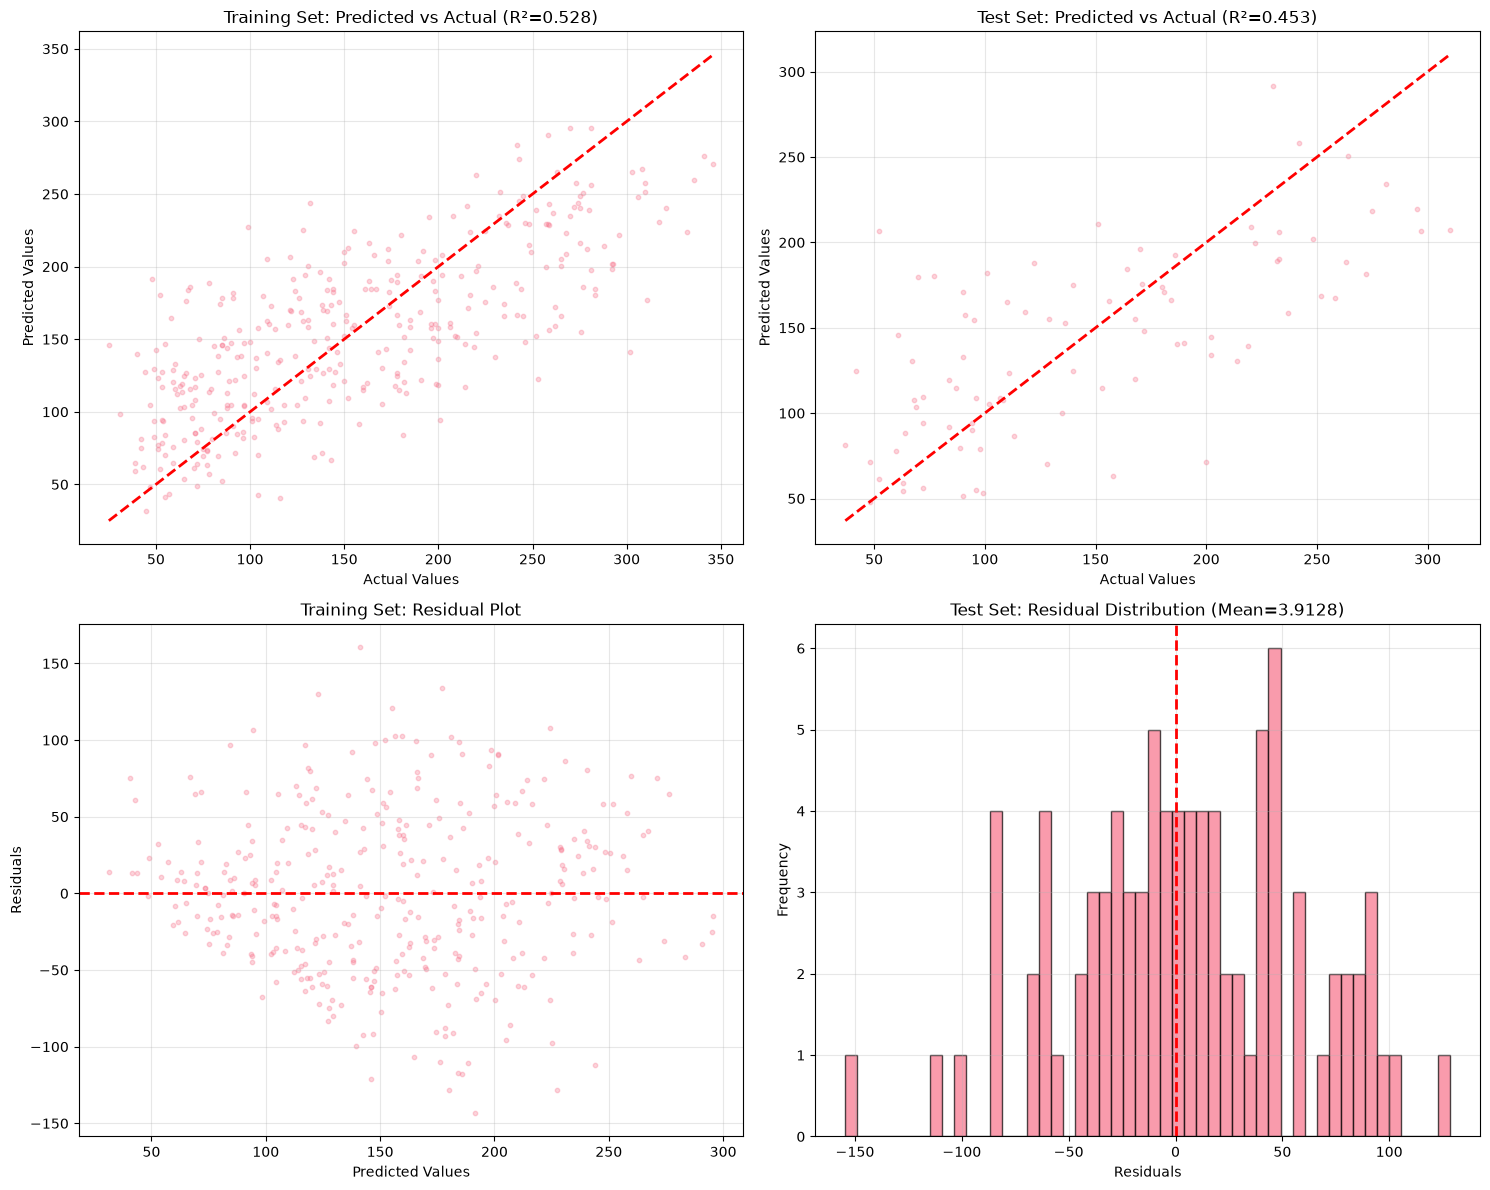

Visual Diagnostics:
1. Top row: Points should be close to the red diagonal line
2. Bottom-left: Residuals should be randomly scattered around 0
3. Bottom-right: Residuals should be normally distributed around 0


In [7]:
# Visualize model performance
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Predicted vs Actual (Training)
axes[0, 0].scatter(y_train, y_train_pred, alpha=0.3, s=10)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
axes[0, 0].set_xlabel('Actual Values')
axes[0, 0].set_ylabel('Predicted Values')
axes[0, 0].set_title(f'Training Set: Predicted vs Actual (R²={train_r2:.3f})')
axes[0, 0].grid(True, alpha=0.3)

# 2. Predicted vs Actual (Test)
axes[0, 1].scatter(y_test, y_test_pred, alpha=0.3, s=10)
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 1].set_xlabel('Actual Values')
axes[0, 1].set_ylabel('Predicted Values')
axes[0, 1].set_title(f'Test Set: Predicted vs Actual (R²={test_r2:.3f})')
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual plot (Training)
train_residuals = y_train - y_train_pred
axes[1, 0].scatter(y_train_pred, train_residuals, alpha=0.3, s=10)
axes[1, 0].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 0].set_xlabel('Predicted Values')
axes[1, 0].set_ylabel('Residuals')
axes[1, 0].set_title('Training Set: Residual Plot')
axes[1, 0].grid(True, alpha=0.3)

# 4. Residual distribution (Test)
test_residuals = y_test - y_test_pred
axes[1, 1].hist(test_residuals, bins=50, edgecolor='black', alpha=0.7)
axes[1, 1].axvline(x=0, color='r', linestyle='--', lw=2)
axes[1, 1].set_xlabel('Residuals')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title(f'Test Set: Residual Distribution (Mean={test_residuals.mean():.4f})')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Visual Diagnostics:")
print("1. Top row: Points should be close to the red diagonal line")
print("2. Bottom-left: Residuals should be randomly scattered around 0")
print("3. Bottom-right: Residuals should be normally distributed around 0")

Model Coefficients:
Intercept: 151.3456

Feature Coefficients:
        Feature  Coefficient
      TotalChol  -931.488846
LogTriglyceride   736.198859
            BMI   542.428759
            LDL   518.062277
         MeanBP   347.703844
   CholHDLRatio   275.317902
            Sex  -241.964362
            HDL   163.419983
   BloodGlucose    48.670657
            Age    37.904021


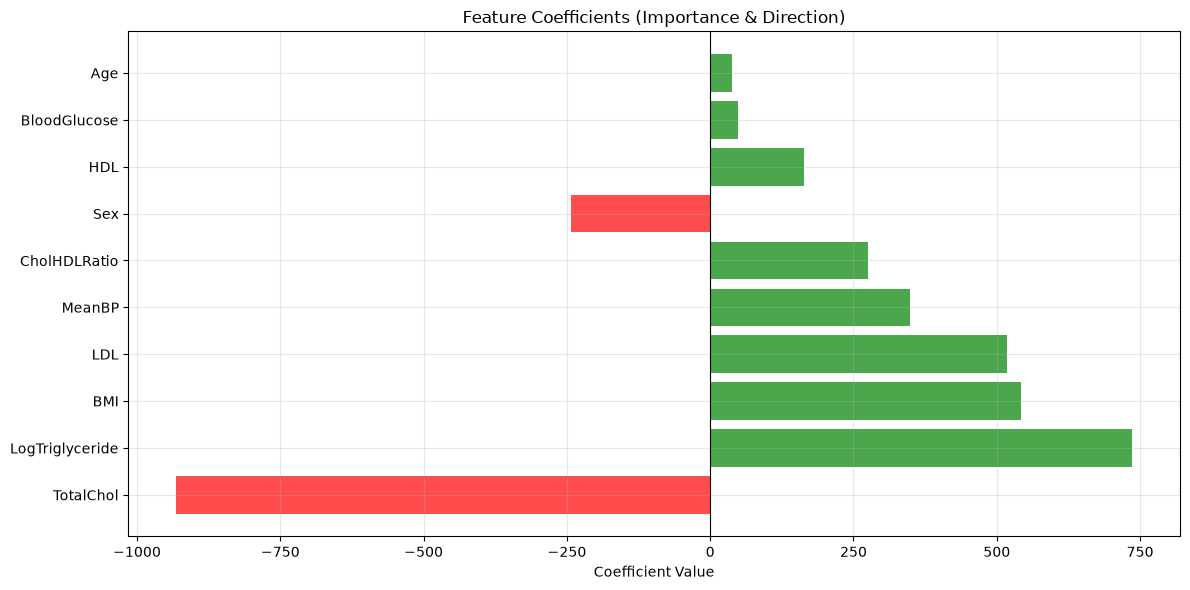


Interpretation:
- Positive coefficients: Feature increase → faster disease progression
- Negative coefficients: Feature increase → slower disease progression
- Example: BMI coefficient = 542.4288
  The ten predictors are pre-scaled, so a coefficient is points of progression
  per unit of the SCALED feature, not per kg/m². Across the range actually
  observed in the cohort, BMI moves the score by about 141 points.


In [8]:
# Analyze coefficients
coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Model Coefficients:")
print(f"Intercept: {lr_model.intercept_:.4f}")
print(f"\nFeature Coefficients:")
print(coefficients.to_string(index=False))

# Visualize coefficients
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['green' if x > 0 else 'red' for x in coefficients['Coefficient']]
ax.barh(coefficients['Feature'], coefficients['Coefficient'], color=colors, alpha=0.7)
ax.set_xlabel('Coefficient Value')
ax.set_title('Feature Coefficients (Importance & Direction)')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("- Positive coefficients: Feature increase → faster disease progression")
print("- Negative coefficients: Feature increase → slower disease progression")
print(f"- Example: BMI coefficient = {coefficients[coefficients['Feature']=='BMI']['Coefficient'].values[0]:.4f}")
print("  The ten predictors are pre-scaled, so a coefficient is points of progression")
print("  per unit of the SCALED feature, not per kg/m². Across the range actually")
print(f"  observed in the cohort, BMI moves the score by about "
      f"{coefficients[coefficients['Feature']=='BMI']['Coefficient'].values[0] * (df['BMI'].max() - df['BMI'].min()):.0f} points.")

---
## 4. Model Assumptions and Diagnostics

Linear regression makes several important assumptions. Let's check them!

### The Five Key Assumptions:

1. **Linearity**: Relationship between X and y is linear
2. **Independence**: Observations are independent
3. **Homoscedasticity**: Constant variance of residuals
4. **Normality**: Residuals are normally distributed
5. **No Multicollinearity**: Features are not highly correlated

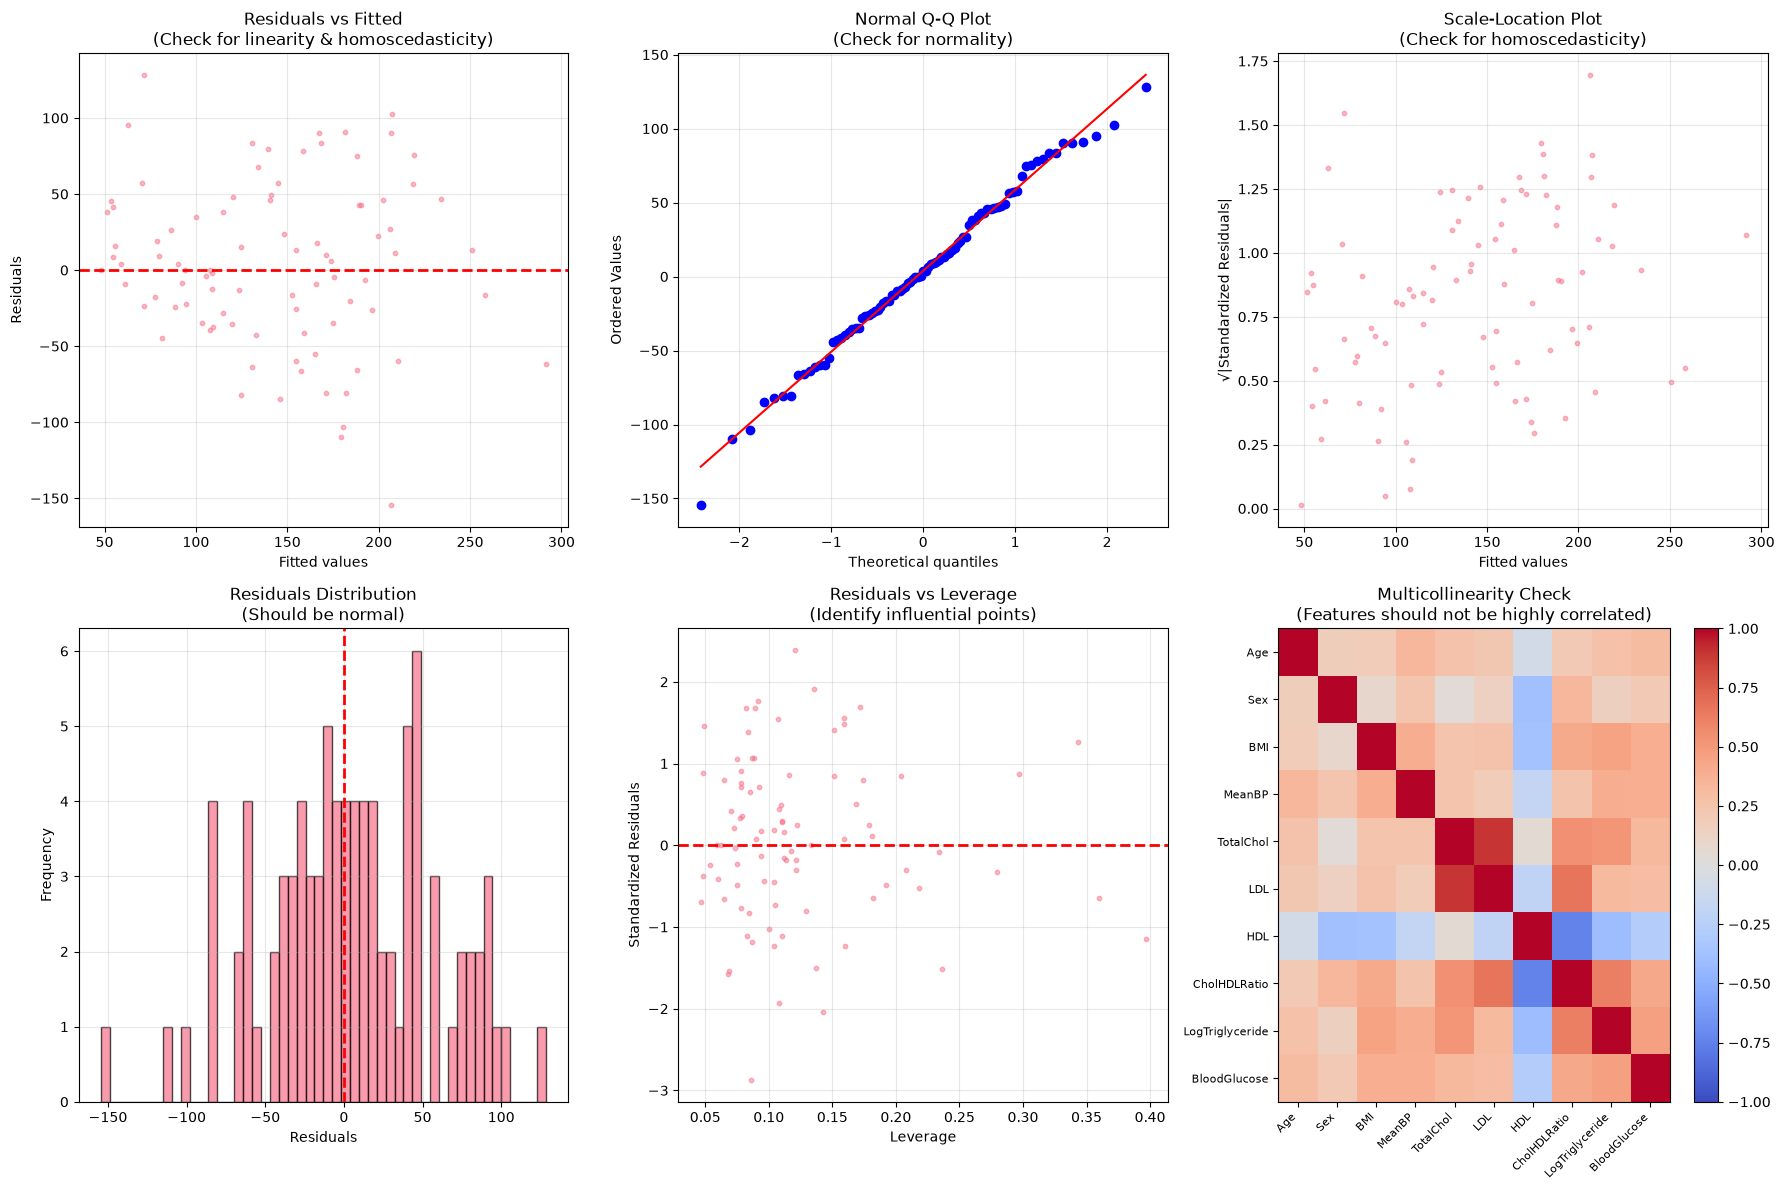

Diagnostic Interpretation Guide:

1. Residuals vs Fitted:
   ✓ Good: Random scatter around 0
   ✗ Bad: Patterns (curve, funnel shape)

2. Q-Q Plot:
   ✓ Good: Points follow the diagonal line
   ✗ Bad: Systematic deviations from line

3. Scale-Location:
   ✓ Good: Horizontal line with equal spread
   ✗ Bad: Increasing/decreasing spread

4. Residuals Distribution:
   ✓ Good: Bell-shaped, centered at 0
   ✗ Bad: Skewed or multi-modal

5. Residuals vs Leverage:
   ✓ Good: No points in extreme corners
   ✗ Bad: High leverage + high residual points

6. Multicollinearity:
   ✓ Good: Low correlations between features
   ✗ Bad: High correlations (|r| > 0.8)


In [9]:
# Comprehensive diagnostics
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Linearity check: Residuals vs Fitted
axes[0, 0].scatter(y_test_pred, test_residuals, alpha=0.5, s=10)
axes[0, 0].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0, 0].set_xlabel('Fitted values')
axes[0, 0].set_ylabel('Residuals')
axes[0, 0].set_title('Residuals vs Fitted\n(Check for linearity & homoscedasticity)')
axes[0, 0].grid(True, alpha=0.3)

# 2. Normality check: Q-Q plot
stats.probplot(test_residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('Normal Q-Q Plot\n(Check for normality)')
axes[0, 1].grid(True, alpha=0.3)

# 3. Scale-Location plot (homoscedasticity)
standardized_residuals = test_residuals / np.std(test_residuals)
axes[0, 2].scatter(y_test_pred, np.sqrt(np.abs(standardized_residuals)), alpha=0.5, s=10)
axes[0, 2].set_xlabel('Fitted values')
axes[0, 2].set_ylabel('√|Standardized Residuals|')
axes[0, 2].set_title('Scale-Location Plot\n(Check for homoscedasticity)')
axes[0, 2].grid(True, alpha=0.3)

# 4. Residuals histogram
axes[1, 0].hist(test_residuals, bins=50, edgecolor='black', alpha=0.7)
axes[1, 0].axvline(x=0, color='r', linestyle='--', lw=2)
axes[1, 0].set_xlabel('Residuals')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Residuals Distribution\n(Should be normal)')
axes[1, 0].grid(True, alpha=0.3)

# 5. Residuals vs Leverage (Cook's distance)
# Calculate leverage
from sklearn.linear_model import LinearRegression
X_test_with_intercept = np.column_stack([np.ones(len(X_test)), X_test])
hat_matrix = X_test_with_intercept @ np.linalg.inv(X_test_with_intercept.T @ X_test_with_intercept) @ X_test_with_intercept.T
leverage = np.diag(hat_matrix)

axes[1, 1].scatter(leverage, standardized_residuals, alpha=0.5, s=10)
axes[1, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1, 1].set_xlabel('Leverage')
axes[1, 1].set_ylabel('Standardized Residuals')
axes[1, 1].set_title('Residuals vs Leverage\n(Identify influential points)')
axes[1, 1].grid(True, alpha=0.3)

# 6. Feature multicollinearity (VIF would go here, but we'll show correlation)
# Show top correlated feature pairs
corr_matrix = df.drop('DiseaseProgression', axis=1).corr()
im = axes[1, 2].imshow(corr_matrix, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
axes[1, 2].set_xticks(range(len(corr_matrix)))
axes[1, 2].set_yticks(range(len(corr_matrix)))
axes[1, 2].set_xticklabels(corr_matrix.columns, rotation=45, ha='right', fontsize=8)
axes[1, 2].set_yticklabels(corr_matrix.columns, fontsize=8)
axes[1, 2].set_title('Multicollinearity Check\n(Features should not be highly correlated)')
plt.colorbar(im, ax=axes[1, 2])

plt.tight_layout()
plt.show()

print("Diagnostic Interpretation Guide:")
print("\n1. Residuals vs Fitted:")
print("   ✓ Good: Random scatter around 0")
print("   ✗ Bad: Patterns (curve, funnel shape)")

print("\n2. Q-Q Plot:")
print("   ✓ Good: Points follow the diagonal line")
print("   ✗ Bad: Systematic deviations from line")

print("\n3. Scale-Location:")
print("   ✓ Good: Horizontal line with equal spread")
print("   ✗ Bad: Increasing/decreasing spread")

print("\n4. Residuals Distribution:")
print("   ✓ Good: Bell-shaped, centered at 0")
print("   ✗ Bad: Skewed or multi-modal")

print("\n5. Residuals vs Leverage:")
print("   ✓ Good: No points in extreme corners")
print("   ✗ Bad: High leverage + high residual points")

print("\n6. Multicollinearity:")
print("   ✓ Good: Low correlations between features")
print("   ✗ Bad: High correlations (|r| > 0.8)")

---
## 5. Advanced Techniques: Regularization

Regularization helps prevent overfitting by penalizing large coefficients.

### Types of Regularization:

1. **Ridge Regression (L2)**:
   $$\min_{\beta} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} \beta_j^2$$
   - Shrinks coefficients toward zero
   - Keeps all features

2. **Lasso Regression (L1)**:
   $$\min_{\beta} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p} |\beta_j|$$
   - Can set coefficients to exactly zero
   - Performs feature selection

3. **Elastic Net**:
   $$\min_{\beta} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \alpha_1 \sum_{j=1}^{p} |\beta_j| + \alpha_2 \sum_{j=1}^{p} \beta_j^2$$
   - Combines L1 and L2
   - Best of both worlds

In [10]:
# Compare different regularization methods
# First, scale features (important for regularization!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train different models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge (α=0.1)': Ridge(alpha=0.1),
    'Ridge (α=1.0)': Ridge(alpha=1.0),
    'Ridge (α=10)': Ridge(alpha=10),
    'Lasso (α=0.01)': Lasso(alpha=0.01),
    'Lasso (α=0.1)': Lasso(alpha=0.1),
    'ElasticNet (α=0.1)': ElasticNet(alpha=0.1, l1_ratio=0.5)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    results.append({
        'Model': name,
        'Train R²': r2_score(y_train, y_pred_train),
        'Test R²': r2_score(y_test, y_pred_test),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, y_pred_train)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, y_pred_test)),
        'Non-zero Coefs': np.sum(np.abs(model.coef_) > 0.001)
    })

results_df = pd.DataFrame(results)
print("Model Comparison with Regularization:")
print(results_df.to_string(index=False))

print("\nNote: Regularization requires feature scaling!")

Model Comparison with Regularization:
             Model  Train R²  Test R²  Train RMSE  Test RMSE  Non-zero Coefs
 Linear Regression  0.527919 0.452603   53.558843  53.853446              10
     Ridge (α=0.1)  0.527915 0.452818   53.559105  53.842869              10
     Ridge (α=1.0)  0.527632 0.454147   53.575145  53.777454              10
      Ridge (α=10)  0.524798 0.457211   53.735609  53.626288              10
    Lasso (α=0.01)  0.527912 0.452947   53.559240  53.836493              10
     Lasso (α=0.1)  0.527221 0.455541   53.598422  53.708698              10
ElasticNet (α=0.1)  0.523618 0.458970   53.802314  53.539343              10

Note: Regularization requires feature scaling!


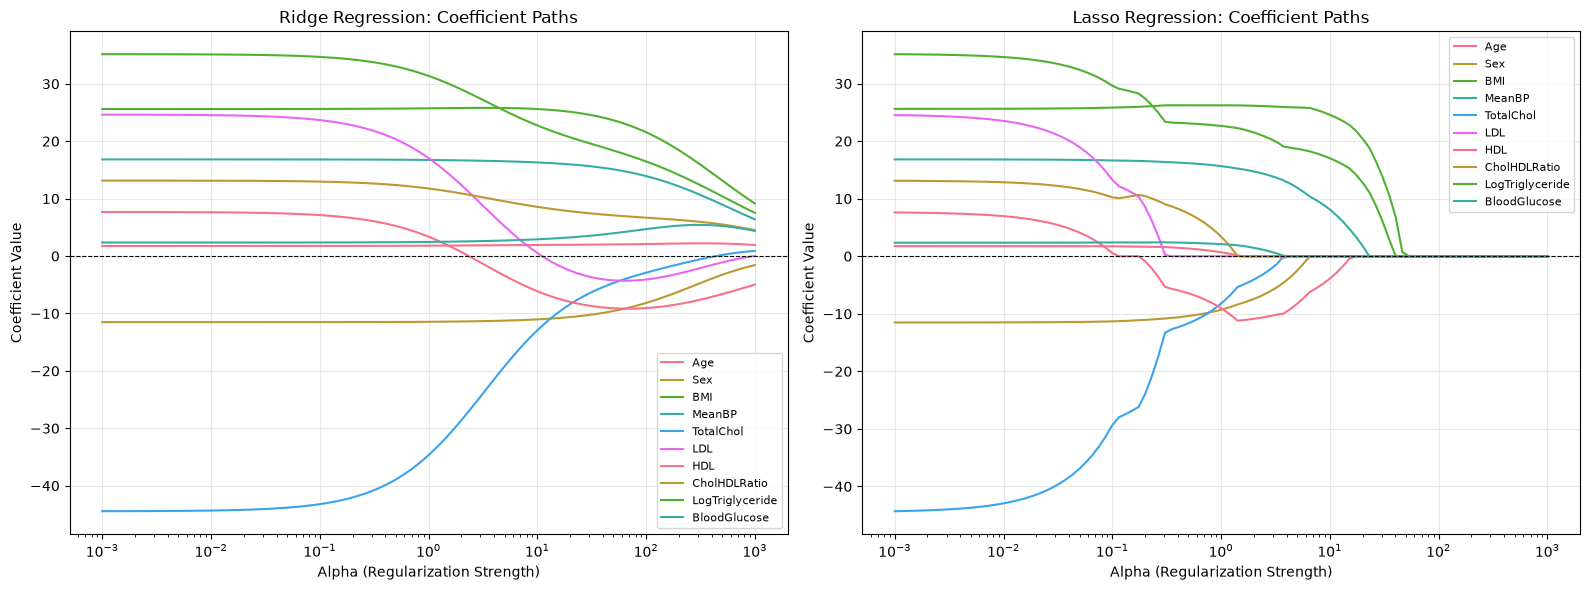

Key Observations:

Ridge Regression:
- Coefficients shrink smoothly toward zero
- All features retained (no coefficients exactly zero)
- Good when all features are potentially useful

Lasso Regression:
- Coefficients can become exactly zero
- Performs automatic feature selection
- Good when some features are irrelevant
- Path shows which features are selected first (most important)


In [11]:
# Visualize coefficient paths
alphas = np.logspace(-3, 3, 100)
ridge_coefs = []
lasso_coefs = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    ridge_coefs.append(ridge.coef_)
    
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)
    lasso_coefs.append(lasso.coef_)

ridge_coefs = np.array(ridge_coefs)
lasso_coefs = np.array(lasso_coefs)

# Plot coefficient paths
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ridge path
for i in range(ridge_coefs.shape[1]):
    axes[0].plot(alphas, ridge_coefs[:, i], label=feature_names[i])
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (Regularization Strength)')
axes[0].set_ylabel('Coefficient Value')
axes[0].set_title('Ridge Regression: Coefficient Paths')
axes[0].legend(loc='best', fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=0, color='black', linestyle='--', linewidth=0.8)

# Lasso path
for i in range(lasso_coefs.shape[1]):
    axes[1].plot(alphas, lasso_coefs[:, i], label=feature_names[i])
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (Regularization Strength)')
axes[1].set_ylabel('Coefficient Value')
axes[1].set_title('Lasso Regression: Coefficient Paths')
axes[1].legend(loc='best', fontsize=8)
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0, color='black', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.show()

print("Key Observations:")
print("\nRidge Regression:")
print("- Coefficients shrink smoothly toward zero")
print("- All features retained (no coefficients exactly zero)")
print("- Good when all features are potentially useful")

print("\nLasso Regression:")
print("- Coefficients can become exactly zero")
print("- Performs automatic feature selection")
print("- Good when some features are irrelevant")
print("- Path shows which features are selected first (most important)")

In [12]:
# Interactive regularization explorer
def explore_regularization(alpha=1.0, model_type='Ridge'):
    # Train model
    if model_type == 'Ridge':
        model = Ridge(alpha=alpha)
    elif model_type == 'Lasso':
        model = Lasso(alpha=alpha, max_iter=10000)
    else:
        model = ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000)
    
    model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    # Metrics
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    
    # Coefficient plot
    coef_df = pd.DataFrame({
        'Feature': feature_names,
        'Coefficient': model.coef_
    }).sort_values('Coefficient', key=abs, ascending=True)
    
    colors = ['green' if x > 0 else 'red' for x in coef_df['Coefficient']]
    axes[0].barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, alpha=0.7)
    axes[0].set_xlabel('Coefficient Value')
    axes[0].set_title(f'{model_type} Coefficients (α={alpha:.3f})')
    axes[0].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    axes[0].grid(True, alpha=0.3)
    
    # Predicted vs Actual
    axes[1].scatter(y_test, y_pred_test, alpha=0.3, s=10)
    axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[1].set_xlabel('Actual Values')
    axes[1].set_ylabel('Predicted Values')
    axes[1].set_title(f'Test Set: R²={test_r2:.4f}')
    axes[1].grid(True, alpha=0.3)
    
    # Performance comparison
    metrics = ['Train R²', 'Test R²', 'Train RMSE', 'Test RMSE']
    values = [train_r2, test_r2, train_rmse, test_rmse]
    colors_bar = ['lightblue', 'lightgreen', 'lightcoral', 'lightyellow']
    axes[2].bar(metrics, values, color=colors_bar, alpha=0.7)
    axes[2].set_ylabel('Value')
    axes[2].set_title('Performance Metrics')
    axes[2].grid(True, alpha=0.3, axis='y')
    
    for i, v in enumerate(values):
        axes[2].text(i, v + 0.02, f"{v:.3f}", ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print(f"\n{model_type} Regression (α={alpha:.3f})")
    print(f"Non-zero coefficients: {np.sum(np.abs(model.coef_) > 0.001)} / {len(model.coef_)}")
    print(f"Test R²: {test_r2:.4f}")
    print(f"Test RMSE: {test_rmse:.1f} progression points")

# Create interactive widget
from ipywidgets import Dropdown
interact(explore_regularization,
         alpha=FloatSlider(value=1.0, min=0.001, max=100, step=0.1, description='Alpha'),
         model_type=Dropdown(options=['Ridge', 'Lasso', 'ElasticNet'], description='Model'));

interactive(children=(FloatSlider(value=1.0, description='Alpha', min=0.001), Dropdown(description='Model', op…

---
## 6. Polynomial Regression

Linear regression can model non-linear relationships using polynomial features!

Many clinical relationships are not straight lines — think of a dose-response curve that
flattens once receptors are saturated, or a risk that rises at both low and high values of
a measurement. The demo below uses a clean synthetic curve so the fitting behaviour is
easy to see.


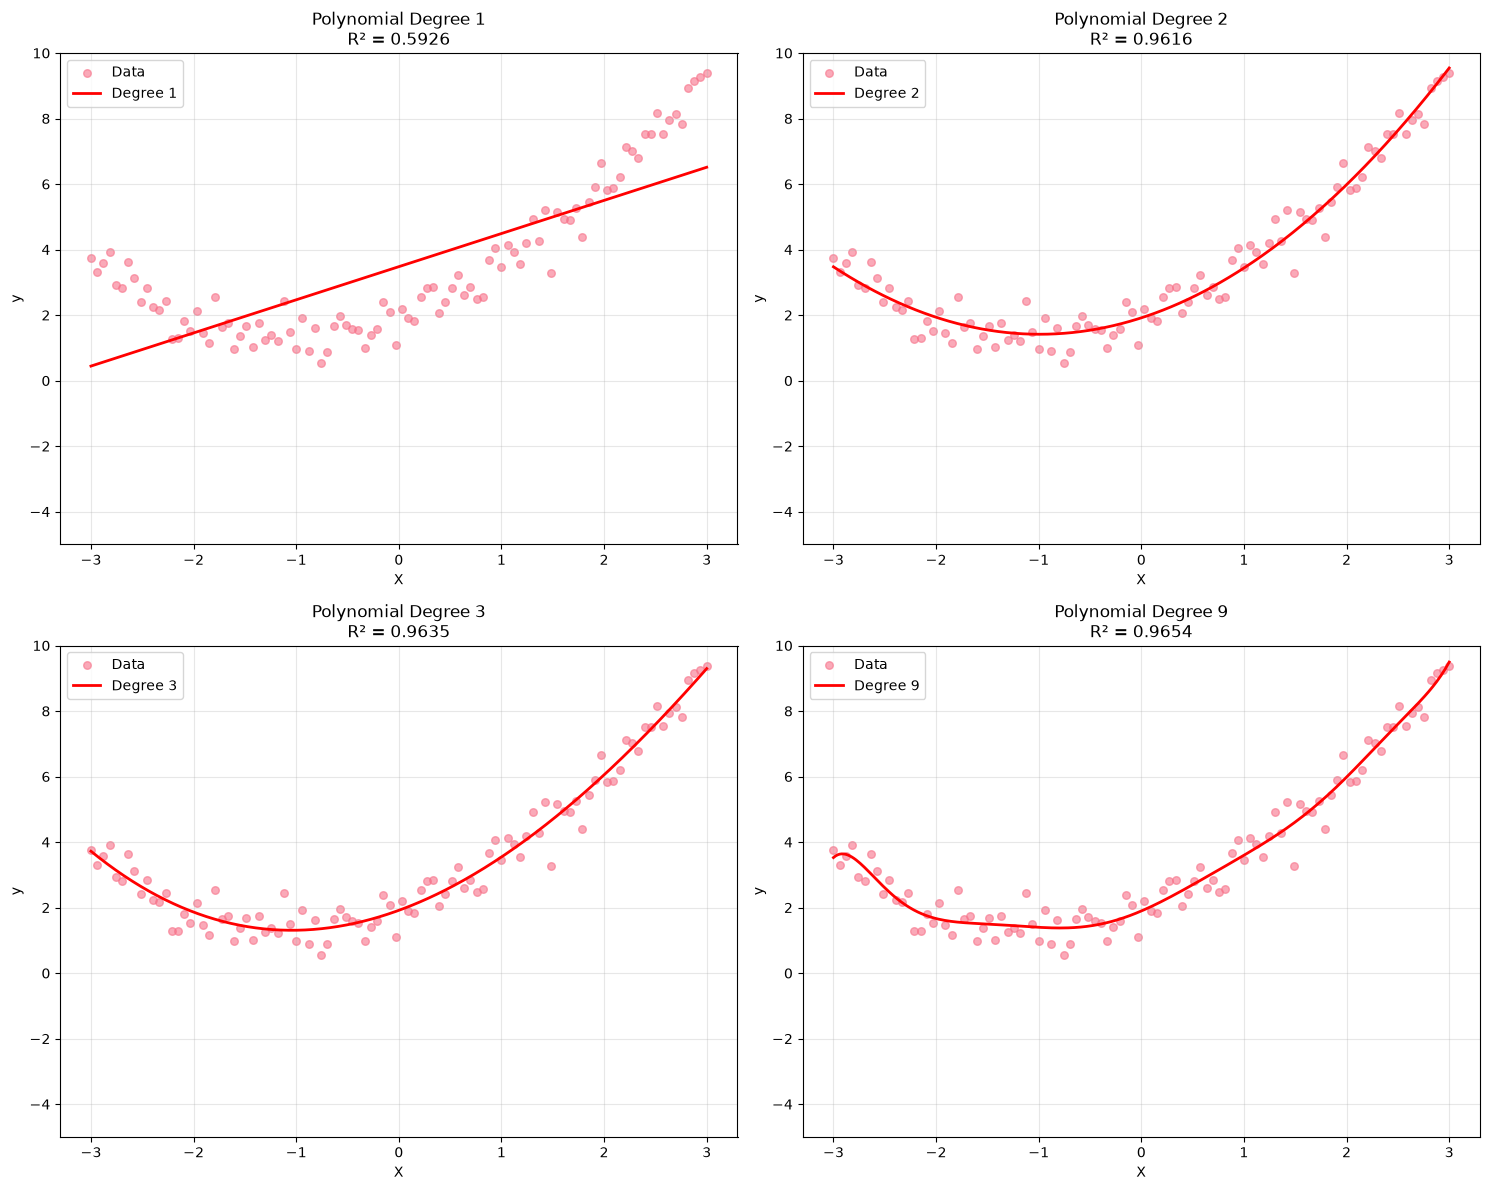

Polynomial Regression Insights:
- Degree 1: Linear - underfits the quadratic relationship
- Degree 2: Quadratic - perfect fit for this data
- Degree 3: Cubic - slight overfitting
- Degree 9: High polynomial - severe overfitting (wiggly curve)

Key takeaway: Higher degree ≠ better model!


In [13]:
# Demonstrate polynomial regression with simple data
np.random.seed(42)
X_poly_demo = np.linspace(-3, 3, 100)
y_poly_demo = 0.5 * X_poly_demo**2 + X_poly_demo + 2 + np.random.normal(0, 0.5, 100)

# Fit models with different polynomial degrees
degrees = [1, 2, 3, 9]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()

for idx, degree in enumerate(degrees):
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X_poly_demo.reshape(-1, 1))
    
    # Fit model
    model = LinearRegression()
    model.fit(X_poly, y_poly_demo)
    
    # Predictions
    X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
    X_plot_poly = poly.transform(X_plot)
    y_plot = model.predict(X_plot_poly)
    
    # Calculate R²
    r2 = r2_score(y_poly_demo, model.predict(X_poly))
    
    # Plot
    axes[idx].scatter(X_poly_demo, y_poly_demo, alpha=0.6, s=30, label='Data')
    axes[idx].plot(X_plot, y_plot, 'r-', linewidth=2, label=f'Degree {degree}')
    axes[idx].set_xlabel('X')
    axes[idx].set_ylabel('y')
    axes[idx].set_title(f'Polynomial Degree {degree}\nR² = {r2:.4f}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim(-5, 10)

plt.tight_layout()
plt.show()

print("Polynomial Regression Insights:")
print("- Degree 1: Linear - underfits the quadratic relationship")
print("- Degree 2: Quadratic - perfect fit for this data")
print("- Degree 3: Cubic - slight overfitting")
print("- Degree 9: High polynomial - severe overfitting (wiggly curve)")
print("\nKey takeaway: Higher degree ≠ better model!")

---
## 7. Real-World Best Practices

### Best Practices Checklist:

#### 1. Data Preparation
- ✅ Handle missing values appropriately
- ✅ Remove or handle outliers
- ✅ Scale features (especially for regularization)
- ✅ Encode categorical variables
- ✅ Check for multicollinearity

#### 2. Model Training
- ✅ Split data properly (train/val/test)
- ✅ Use cross-validation
- ✅ Try regularization (Ridge, Lasso)
- ✅ Start simple, add complexity if needed

#### 3. Model Evaluation
- ✅ Check multiple metrics (R², RMSE, MAE)
- ✅ Validate assumptions
- ✅ Examine residual plots
- ✅ Look for influential points
- ✅ Test on holdout set

#### 4. Model Interpretation
- ✅ Understand coefficient meanings
- ✅ Check statistical significance
- ✅ Consider domain knowledge
- ✅ Document assumptions and limitations

In [14]:
# Example: Complete workflow with best practices
print("Complete Linear Regression Workflow")
print("="*50)

# 1. Data preparation
print("\n1. Data Preparation")
print("   - Checking for missing values...")
print(f"   - Missing values: {np.isnan(X).sum()}")
print("   - Scaling features...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Train/test split with stratification
print("\n2. Data Splitting")
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)
print(f"   - Training samples: {len(X_train_final)}")
print(f"   - Test samples: {len(X_test_final)}")

# 3. Cross-validation to select best regularization
print("\n3. Model Selection via Cross-Validation")
alphas = [0.001, 0.01, 0.1, 1.0, 10.0]
best_alpha = None
best_score = -np.inf

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    scores = cross_val_score(ridge, X_train_final, y_train_final, cv=5, scoring='r2')
    mean_score = scores.mean()
    print(f"   - Ridge(α={alpha:5.3f}): CV R² = {mean_score:.4f} ± {scores.std():.4f}")
    
    if mean_score > best_score:
        best_score = mean_score
        best_alpha = alpha

print(f"\n   - Best α: {best_alpha} (CV R² = {best_score:.4f})")

# 4. Train final model
print("\n4. Training Final Model")
final_model = Ridge(alpha=best_alpha)
final_model.fit(X_train_final, y_train_final)

# 5. Evaluate
print("\n5. Final Evaluation")
y_train_pred_final = final_model.predict(X_train_final)
y_test_pred_final = final_model.predict(X_test_final)

print(f"   - Train R²: {r2_score(y_train_final, y_train_pred_final):.4f}")
print(f"   - Test R²:  {r2_score(y_test_final, y_test_pred_final):.4f}")
print(f"   - Test RMSE: {np.sqrt(mean_squared_error(y_test_final, y_test_pred_final)):.1f} progression points")
print(f"   - Test MAE:  {mean_absolute_error(y_test_final, y_test_pred_final):.1f} progression points")

# 6. Assumptions check
print("\n6. Assumptions Validation")
test_residuals_final = y_test_final - y_test_pred_final
_, p_value = stats.normaltest(test_residuals_final)
print(f"   - Normality test p-value: {p_value:.4f}")
print(f"   - {'✓' if p_value > 0.05 else '✗'} Residuals appear normally distributed" if p_value > 0.05 else f"   - {'✗'} Residuals may not be normally distributed")

print("\n" + "="*50)
print("Workflow complete! Model ready for deployment.")
print("="*50)

Complete Linear Regression Workflow

1. Data Preparation
   - Checking for missing values...
   - Missing values: 0
   - Scaling features...

2. Data Splitting
   - Training samples: 353
   - Test samples: 89

3. Model Selection via Cross-Validation
   - Ridge(α=0.001): CV R² = 0.4493 ± 0.1441
   - Ridge(α=0.010): CV R² = 0.4493 ± 0.1440
   - Ridge(α=0.100): CV R² = 0.4496 ± 0.1433
   - Ridge(α=1.000): CV R² = 0.4512 ± 0.1388
   - Ridge(α=10.000): CV R² = 0.4539 ± 0.1297

   - Best α: 10.0 (CV R² = 0.4539)

4. Training Final Model

5. Final Evaluation
   - Train R²: 0.5248
   - Test R²:  0.4572
   - Test RMSE: 53.6 progression points
   - Test MAE:  42.9 progression points

6. Assumptions Validation
   - Normality test p-value: 0.8107
   - ✓ Residuals appear normally distributed

Workflow complete! Model ready for deployment.


---
## Summary and Key Takeaways

### Key Points:

1. **Linear Regression Fundamentals**:
   - Simple, interpretable, and fast
   - Models linear relationships: y = β₀ + β₁x₁ + ... + βₙxₙ
   - Coefficients show feature impact and direction

2. **Important Metrics**:
   - **R²**: Proportion of variance explained (0 to 1)
   - **RMSE**: Average prediction error (same units as target)
   - **MAE**: Mean absolute error (robust to outliers)

3. **Key Assumptions** (check these!):
   - Linearity
   - Independence
   - Homoscedasticity (constant variance)
   - Normality of residuals
   - No multicollinearity

4. **When Assumptions Fail**:
   - Transform features (log, sqrt, etc.)
   - Use polynomial features
   - Try robust regression
   - Consider other algorithms

5. **Regularization**:
   - **Ridge**: Shrinks coefficients, keeps all features
   - **Lasso**: Can zero out coefficients, feature selection
   - **ElasticNet**: Combines both approaches
   - Always scale features for regularization!

6. **Best Practices**:
   - Start simple, add complexity only if needed
   - Always validate assumptions
   - Use cross-validation
   - Scale features for regularization
   - Check residual plots
   - Interpret coefficients carefully

### Next Steps:
- Practice with different datasets
- Explore feature engineering techniques
- Learn logistic regression for classification
- Study time series regression
- Compare with tree-based models

### Additional Resources:
- [Scikit-learn Linear Models](https://scikit-learn.org/stable/modules/linear_model.html)
- [Introduction to Statistical Learning](https://www.statlearning.com/)
- [Regression Diagnostics](https://en.wikipedia.org/wiki/Regression_diagnostic)

In [15]:
print("🎉 LINEAR REGRESSION TUTORIAL COMPLETE! 🎉")
print("\n📊 What We Covered:")
print("  ✅ Mathematical foundations from first principles")
print("  ✅ Hands-on implementation with real data")
print("  ✅ Model evaluation and interpretation")
print("  ✅ Assumption checking and diagnostics")
print("  ✅ Regularization techniques (Ridge, Lasso, ElasticNet)")
print("  ✅ Polynomial regression for non-linear relationships")
print("  ✅ Real-world best practices")
print("\n🚀 You're now ready to use Linear Regression effectively!")
print("\n💡 Remember: Linear regression is often the best starting point.")
print("   Start simple, validate assumptions, then add complexity if needed.")

🎉 LINEAR REGRESSION TUTORIAL COMPLETE! 🎉

📊 What We Covered:
  ✅ Mathematical foundations from first principles
  ✅ Hands-on implementation with real data
  ✅ Model evaluation and interpretation
  ✅ Assumption checking and diagnostics
  ✅ Regularization techniques (Ridge, Lasso, ElasticNet)
  ✅ Polynomial regression for non-linear relationships
  ✅ Real-world best practices

🚀 You're now ready to use Linear Regression effectively!

💡 Remember: Linear regression is often the best starting point.
   Start simple, validate assumptions, then add complexity if needed.
